## K NEAREST NEIGHBOUR

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ds = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

In [3]:
ds.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [4]:
category = {
    'Normal_Weight': 0,
    'Overweight_Level_I': 1,
    'Overweight_Level_II': 2,
    'Obesity_Type_I': 3,
    'Insufficient_Weight': 4,
    'Obesity_Type_II': 5,
    'Obesity_Type_III': 6
}

In [5]:
ds['NObeyesdad'] = ds['NObeyesdad'].map(category)

In [6]:
for col in ds.select_dtypes(include=['object']).columns:
    ds[col] = ds[col].astype('category').cat.codes

In [7]:
X = ds.drop('NObeyesdad', axis=1).values
y = ds['NObeyesdad'].values

In [8]:
X = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))

In [9]:
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state:
        np.random.seed(random_state)
    indices = np.random.permutation(len(X))
    test_size = int(len(X) * test_size)
    test_idx = indices[:test_size]
    train_idx = indices[test_size:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

class KNN_Euclidean:
    def __init__(self, k):
        self.k = k
    def fit(self, X_train, y_train):
        self.X_train = X_train  
        self.y_train = y_train  

    def predict(self, X_test):
        predictions = []
        for test_point in X_test:          
            distances = [(euclidean_distance(test_point, train_point), label) 
                         for train_point, label in zip(self.X_train, self.y_train)]

            distances.sort(key=lambda x: x[0])
            
            k_nearest = [label for _, label in distances[:self.k]]
            
            prediction = max(set(k_nearest), key=k_nearest.count)
            predictions.append(prediction)
        
        return np.array(predictions)

In [24]:
k=3
knn=KNN_Euclidean(k)
knn.fit(X_train,y_train)
y_new=knn.predict(X_test)
accuracy =np.mean(y_new==y_test) 
print(f"The accuracy of the k-NN algorithm is: {accuracy * 100:.2f}%")

The accuracy of the k-NN algorithm is: 77.96%


In [25]:
k=5
knn=KNN_Euclidean(k)
knn.fit(X_train,y_train)
y_new=knn.predict(X_test)
accuracy =np.mean(y_new==y_test) 
print(f"The accuracy of the k-NN algorithm is: {accuracy * 100:.2f}%")

The accuracy of the k-NN algorithm is: 76.07%


In [26]:
k=7
knn=KNN_Euclidean(k)
knn.fit(X_train,y_train)
y_new=knn.predict(X_test)
accuracy =np.mean(y_new==y_test) 
print(f"The accuracy of the k-NN algorithm is: {accuracy * 100:.2f}%")

The accuracy of the k-NN algorithm is: 73.93%


In [27]:
k=9
knn=KNN_Euclidean(k)
knn.fit(X_train,y_train)
y_new=knn.predict(X_test)
accuracy =np.mean(y_new==y_test) 
print(f"The accuracy of the k-NN algorithm is: {accuracy * 100:.2f}%")

The accuracy of the k-NN algorithm is: 71.80%


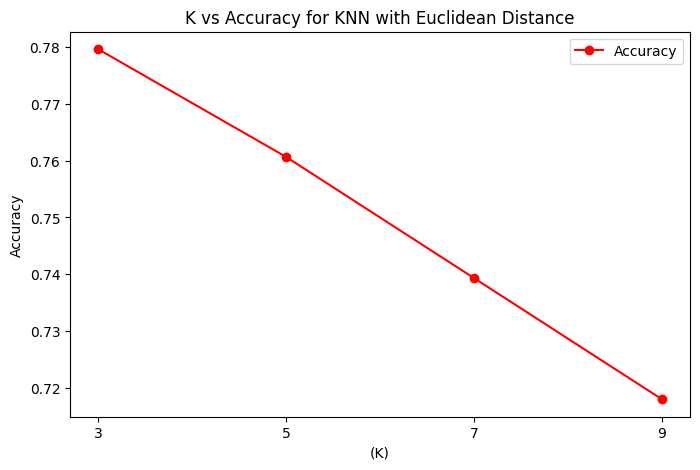

In [37]:
k_values = range(3,11,2) 
accuracies = []

for k in k_values:
    knn = KNN_Euclidean(k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    
    accuracy = np.mean(y_pred == y_test)
    accuracies.append(accuracy)
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='r', label="Accuracy")
plt.xlabel("(K)")
plt.ylabel("Accuracy")
plt.title("K vs Accuracy for KNN with Euclidean Distance")
plt.xticks(k_values)
plt.legend()
plt.show()

In [29]:
def manhattan_distance(x1, x2):
    return np.sum(np.abs((x1 - x2)))
    
class KNN_Manhattan:
    def __init__(self,k=3):
        self.k=k
    
        

    def fit(self,X_train, y_train):
        self.X_train=X_train
        self.y_train=y_train

    def predict(self,X_test):
        predictions=[]
        for test_point in X_test:
            
            distances = [(manhattan_distance(test_point, train_point), label)
                         
                         
                         for train_point, label in zip(self.X_train, self.y_train)]

            
    
            distances.sort(key=lambda x: x[0])
            k_nearest= [label for (_, label) in distances[:self.k]]


            predictions.append(max(set(k_nearest), key=k_nearest.count))
        return np.array(predictions)


In [30]:
k=3
knn = KNN_Manhattan(k)
knn.fit(X_train,y_train)
y_new = knn.predict(X_test)
accuracy = np.mean(y_new==y_test) 
print(f"The accuracy of the k-NN algorithm is: {accuracy * 100:.2f}%")

The accuracy of the k-NN algorithm is: 84.83%


In [31]:
k=5
knn = KNN_Manhattan(k)
knn.fit(X_train,y_train)
y_new = knn.predict(X_test)
accuracy = np.mean(y_new==y_test) 
print(f"The accuracy of the k-NN algorithm is: {accuracy * 100:.2f}%")

The accuracy of the k-NN algorithm is: 84.12%


In [32]:
k=7
knn = KNN_Manhattan(k)
knn.fit(X_train,y_train)
y_new = knn.predict(X_test)
accuracy = np.mean(y_new==y_test) 
print(f"The accuracy of the k-NN algorithm is: {accuracy * 100:.2f}%")

The accuracy of the k-NN algorithm is: 82.94%


In [19]:
k=9
knn = KNN_Manhattan(k)
knn.fit(X_train,y_train)
y_new = knn.predict(X_test)
accuracy = np.mean(y_new==y_test) 
print(f"The accuracy of the k-NN algorithm is: {accuracy * 100:.2f}%")

The accuracy of the k-NN algorithm is: 81.52%


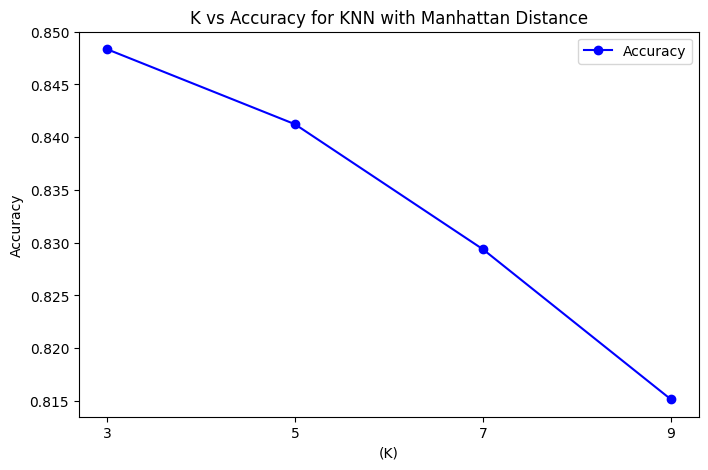

In [33]:
k_values = range(3,11,2) 
accuracies = []

for k in k_values:
    knn = KNN_Manhattan(k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    
    accuracy = np.mean(y_pred == y_test)
    accuracies.append(accuracy)
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='b', label="Accuracy")
plt.xlabel("(K)")
plt.ylabel("Accuracy")
plt.title("K vs Accuracy for KNN with Manhattan Distance")
plt.xticks(k_values)
plt.legend()
plt.show()

In [35]:
def minkowski_distance(x1, x2, p=3):
    return np.sum(np.abs(x1 - x2) ** p) ** (1 / p)

class KNN_Minkowski:
    def __init__(self, k, p=2):  
        self.k = k
        self.p = p

    def fit(self, X_train, y_train):
        self.X_train = X_train
        self.y_train = y_train

    def predict(self, X_test):
        predictions = []
        for test_point in X_test:

            distances = [(minkowski_distance(test_point, train_point, self.p), label) 
                         for train_point, label in zip(self.X_train, self.y_train)]

            distances.sort(key=lambda x: x[0])
            k_nearest = [label for _, label in distances[:self.k]]
            prediction = max(set(k_nearest), key=k_nearest.count)
            predictions.append(prediction)
        
        return np.array(predictions)

In [40]:
k = 3
knn = KNN_Minkowski(k, p)
knn.fit(X_train, y_train)
y_new = knn.predict(X_test)

accuracy = np.mean(y_new == y_test)
print(f"The accuracy of the k-NN algorithm is: {accuracy * 100:.2f}%")


The accuracy of the k-NN algorithm is: 77.96%


In [38]:
k = 5
knn = KNN_Minkowski(k)
knn.fit(X_train, y_train)  
y_pred = knn.predict(X_test)  
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 76.07%


In [39]:
k = 7
knn = KNN_Minkowski(k)
knn.fit(X_train, y_train)  
y_pred = knn.predict(X_test)  
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 73.93%


In [41]:
k = 9
knn = KNN_Minkowski(k)
knn.fit(X_train, y_train)  
y_pred = knn.predict(X_test)  
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 71.80%


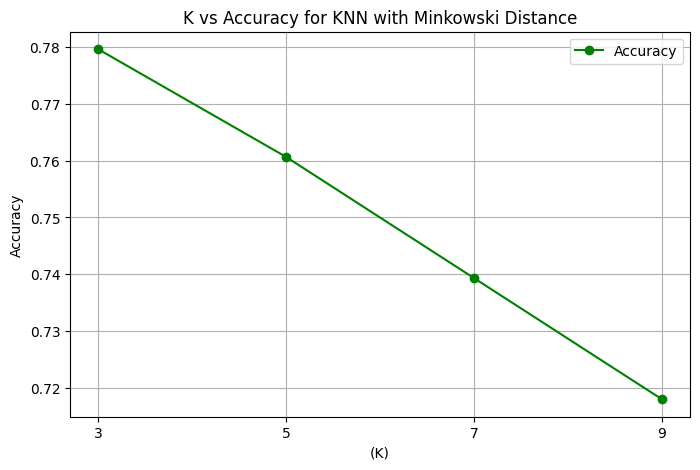

In [44]:
k_values = range(3,11,2) 
accuracies = []

for k in k_values:
    knn = KNN_Minkowski(k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    
    accuracy = np.mean(y_pred == y_test)
    accuracies.append(accuracy)
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='g', label="Accuracy")
plt.xlabel("(K)")
plt.ylabel("Accuracy")
plt.title("K vs Accuracy for KNN with Minkowski Distance")
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

In [46]:
def chebyshev_distance(x1, x2):
    return np.max(np.abs(x1 - x2))

class KNN_Chebyshev:
    def __init__(self, k):
        self.k = k

    def fit(self, X_train, y_train):
        self.X_train = X_train
        self.y_train = y_train

    def predict(self, X_test):
        predictions = []
        for test_point in X_test:
            distances = [(chebyshev_distance(test_point, train_point), label) 
                         for train_point, label in zip(self.X_train, self.y_train)]
            distances.sort(key=lambda x: x[0])
            k_nearest = [label for _, label in distances[:self.k]]
            prediction = max(set(k_nearest), key=k_nearest.count)
            predictions.append(prediction)
        
        return np.array(predictions)

In [47]:
k = 3
knn = KNN_Chebyshev(k)
knn.fit(X_train, y_train)  
y_pred = knn.predict(X_test)  
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 69.67%


In [48]:
k = 5
knn = KNN_Chebyshev(k)
knn.fit(X_train, y_train)  
y_pred = knn.predict(X_test)  
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 68.96%


In [49]:
k = 7
knn = KNN_Chebyshev(k)
knn.fit(X_train, y_train)  
y_pred = knn.predict(X_test)  
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 68.01%


In [50]:
k = 9
knn = KNN_Chebyshev(k)
knn.fit(X_train, y_train)  
y_pred = knn.predict(X_test)  
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 64.45%


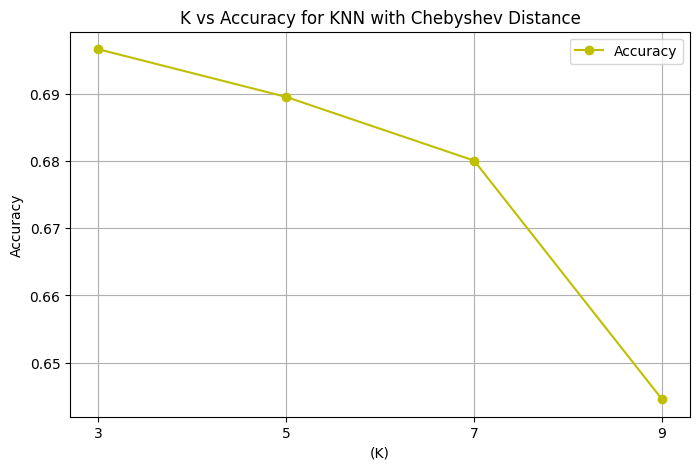

In [53]:
k_values = range(3,11,2) 
accuracies = []

for k in k_values:
    knn = KNN_Chebyshev(k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    
    accuracy = np.mean(y_pred == y_test)
    accuracies.append(accuracy)
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='y', label="Accuracy")
plt.xlabel("(K)")
plt.ylabel("Accuracy")
plt.title("K vs Accuracy for KNN with Chebyshev Distance")
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

In [55]:
class KNN_cosine_similarity:
    def __init__(self, k=3):
        self.k = k
        self.X_train = None
        self.y_train = None
    
    def fit(self, X, y):
        self.X_train = np.array(X)
        self.y_train = np.array(y)
    
    def cosine_similarity(self, x1, x2):
        dot_product = np.dot(x1, x2)
        norm_x1 = np.linalg.norm(x1)
        norm_x2 = np.linalg.norm(x2)
        return dot_product / (norm_x1 * norm_x2)
    
    def predict(self, X):
        X = np.array(X)
        predictions = []
        
        for x in X:
            similarities = [self.cosine_similarity(x, x_train) for x_train in self.X_train]
            
            top_k_indices = np.argsort(similarities)[-self.k:]
            top_k_labels = [self.y_train[i] for i in top_k_indices]
            
            label_counts = {}
            for label in top_k_labels:
                if label in label_counts:
                    label_counts[label] += 1
                else:
                    label_counts[label] = 1
            
            most_common = max(label_counts, key=label_counts.get)
            predictions.append(most_common)
        
        return predictions

In [56]:
k = 3
knn = KNN_cosine_similarity(k)
knn.fit(X_train, y_train)  
y_pred = knn.predict(X_test)  
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 75.36%


In [57]:
k = 5
knn = KNN_cosine_similarity(k)
knn.fit(X_train, y_train)  
y_pred = knn.predict(X_test)  
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 74.17%


In [58]:
k = 7
knn = KNN_cosine_similarity(k)
knn.fit(X_train, y_train)  
y_pred = knn.predict(X_test)  
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 72.99%


In [59]:
k = 9
knn = KNN_cosine_similarity(k)
knn.fit(X_train, y_train)  
y_pred = knn.predict(X_test)  
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 70.85%


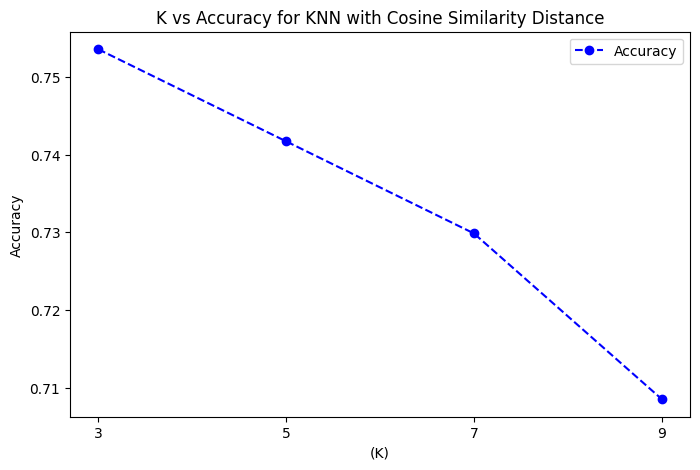

In [61]:
k_values = range(3,11,2) 
accuracies = []

for k in k_values:
    knn = KNN_cosine_similarity(k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    
    accuracy = np.mean(y_pred == y_test)
    accuracies.append(accuracy)
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='--', color='b', label="Accuracy")
plt.xlabel("(K)")
plt.ylabel("Accuracy")
plt.title("K vs Accuracy for KNN with Cosine Similarity Distance")
plt.xticks(k_values)
plt.legend()
plt.show()

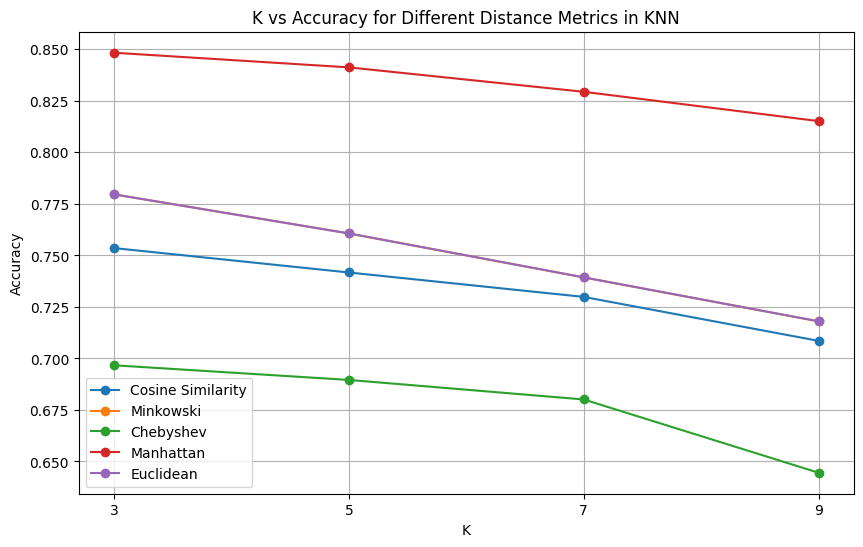

In [62]:
classifiers = {
    'Cosine Similarity': KNN_cosine_similarity,
    'Minkowski': KNN_Minkowski,
    'Chebyshev': KNN_Chebyshev,
    'Manhattan': KNN_Manhattan,
    'Euclidean': KNN_Euclidean
}

k_values = [3, 5, 7, 9]
plt.figure(figsize=(10, 6))

for name, KNNClass in classifiers.items():
    accuracies = []
    
    for k in k_values:
        knn = KNNClass(k)
        knn.fit(X_train, y_train)
        y_pred = knn.predict(X_test)
        accuracy = np.mean(y_pred == y_test)
        accuracies.append(accuracy)
    
    plt.plot(k_values, accuracies, marker='o', linestyle='-', label=name)

plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("K vs Accuracy for Different Distance Metrics in KNN")
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()


In [63]:
def plot_confusion_matrix(Y_true, Y_pred, classes):
    
    cm = np.zeros((len(classes), len(classes)))
    
    for i in range(len(y_true)):
    
        cm[y_true[i], y_pred[i]] += 1
    

    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title("Confusion Matrix")
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes)
    plt.yticks(tick_marks, classes)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    

    for i in range(cm.shape[0]):
        
        for j in range(cm.shape[1]):
            
            plt.text(j, i, str(cm[i, j]), horizontalalignment="center",color="white" if cm[i, j] > cm.max()/2 else "black")
    plt.show()
                  


    

In [64]:
plt.show()